# ARTI 402 — Deep Learning
## Lab 9 — Autoencoders: Learning Without Labels

**Week 9 · Autoencoders and Representation Learning**
Autoencoders, the bottleneck, denoising, and multitask learning.

| | |
|---|---|
| **Prerequisites** | Lab 8. You will reuse your PyTorch training loop almost unchanged |
| **Reference** | Ekman, *Learning Deep Learning*, Chapter 17 and the PyTorch documentation|


### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [Arxiv Insights — *Variational Autoencoders*](https://www.youtube.com/watch?v=9zKuYvjFFS8) | Watch the first 6 minutes only. The plain autoencoder part |
| **Stage 1** | [Google ML — Autoencoders](https://developers.google.com/machine-learning/crash-course/autoencoders) | Short, clear, with pictures |
| **Stage 4** | [TensorFlow Embedding Projector](https://projector.tensorflow.org/) | Fly around a real latent space. Pick MNIST from the dropdown |
| **Reference** | [PyTorch — `nn.Sequential`](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) | The tidy way to stack layers |

### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* All six exercises and both checkpoints are completed. Keep the preceding cells because later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* This supplied file ends after the denoising stage and closing summary; it contains no separate assessment section.


---
## Setup


In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
torch.set_num_threads(1)
print('PyTorch :', torch.__version__)
digits = load_digits()
X = digits.data / 16.0
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
Xtr = torch.tensor(X_train, dtype=torch.float32)
Xte = torch.tensor(X_test, dtype=torch.float32)
print('\ntrain:', X_train.shape, ' test:', X_test.shape)
print('each image is 8 x 8 =', X.shape[1], 'pixels, flattened into a row')
print('\nSetup OK')


PyTorch : 2.9.0+cpu

train: (1347, 64)  test: (450, 64)
each image is 8 x 8 = 64 pixels, flattened into a row

Setup OK


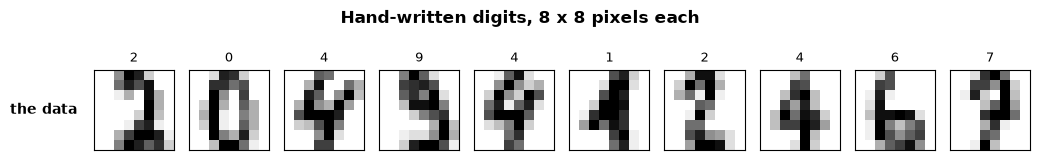

In [ ]:
LEARN = '#E8A33D'
FIXED = '#8FB8D6'
EDGE = '#333333'
TRAIN_C = '#2E86C1'
VAL_C = '#C0392B'

def draw_autoencoder_architecture(dims=(64, 32, 8, 32, 64)):
    fig, ax = plt.subplots(figsize=(11.5, 4.3))
    n = len(dims)
    xs = np.linspace(0.6, 10.4, n)
    biggest = max(dims)
    labels = ['input\n(the image)', 'hidden', 'code\n(bottleneck)', 'hidden', 'output\n(the rebuilt image)']
    for i, (x, d) in enumerate(zip(xs, dims)):
        h = 2.5 * (d / biggest) ** 0.55
        col = FIXED if i in (0, n - 1) else LEARN
        ax.add_patch(plt.Rectangle((x - 0.42, -h / 2), 0.84, h, facecolor=col, edgecolor=EDGE, lw=1.4, zorder=4))
        ax.text(x, 0, str(d), ha='center', va='center', fontsize=11.5, weight='bold', zorder=6)
        ax.text(x, -h / 2 - 0.33, labels[i], ha='center', va='top', fontsize=9.2)
    for x0, x1 in zip(xs[:-1], xs[1:]):
        ax.annotate('', xy=(x1 - 0.46, 0), xytext=(x0 + 0.46, 0), arrowprops=dict(arrowstyle='-|>', color='#555', lw=1.5))
    mid = (xs[0] + xs[2]) / 2
    ax.text(mid, 1.78, 'ENCODER', ha='center', fontsize=11, weight='bold', color='#B5651D')
    ax.annotate('', xy=(xs[2] - 0.3, 1.55), xytext=(xs[0] + 0.1, 1.55), arrowprops=dict(arrowstyle='-|>', color='#B5651D', lw=1.6))
    mid2 = (xs[2] + xs[4]) / 2
    ax.text(mid2, 1.78, 'DECODER', ha='center', fontsize=11, weight='bold', color='#B5651D')
    ax.annotate('', xy=(xs[4] - 0.1, 1.55), xytext=(xs[2] + 0.3, 1.55), arrowprops=dict(arrowstyle='-|>', color='#B5651D', lw=1.6))
    ax.annotate('', xy=(xs[0], -2.05), xytext=(xs[4], -2.05), arrowprops=dict(arrowstyle='<|-|>', color='#C0392B', lw=1.5, linestyle=':'))
    ax.text((xs[0] + xs[4]) / 2, -2.3, 'the loss compares these two  —  the target IS the input', ha='center', va='top', fontsize=10, weight='bold', color='#C0392B')
    ax.set_xlim(0, 11)
    ax.set_ylim(-3.1, 2.35)
    ax.axis('off')
    ax.set_title('An autoencoder: squeeze it through the middle, then rebuild it', fontsize=12.5, weight='bold', pad=12)
    plt.tight_layout()
    return fig

def draw_digit_grid(rows, n=10, side=8, titles=None, suptitle='Original and reconstruction'):
    k = len(rows)
    fig, axes = plt.subplots(k, n, figsize=(1.05 * n, 1.18 * k + 0.5), squeeze=False)
    for r, (label, data) in enumerate(rows):
        for c in range(n):
            ax = axes[r][c]
            ax.imshow(np.asarray(data)[c].reshape(side, side), cmap='gray_r', vmin=0, vmax=1, interpolation='nearest')
            ax.set_xticks([])
            ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(str(titles[c]), fontsize=9)
        axes[r][0].set_ylabel(label, fontsize=10, weight='bold', rotation=0, ha='right', va='center', labelpad=12)
    fig.suptitle(suptitle, fontsize=12.5, weight='bold', y=1.0)
    plt.tight_layout()
    return fig

def draw_latent_space(Z, labels, title='The 2-D code, coloured by digit'):
    fig, ax = plt.subplots(figsize=(7.2, 6.0))
    Z = np.asarray(Z)
    labels = np.asarray(labels)
    classes = np.unique(labels)
    cmap = plt.get_cmap('tab10')
    for c in classes:
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.75, color=cmap(int(c) % 10), edgecolor='none', label=str(c))
    ax.legend(title='digit', fontsize=8.5, title_fontsize=9, markerscale=1.4, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    ax.set_xlabel('code dimension 1')
    ax.set_ylabel('code dimension 2')
    ax.grid(alpha=0.25)
    ax.set_title(title, fontsize=12.5, weight='bold')
    plt.tight_layout()
    return fig

def draw_bottleneck_sweep(sizes, train_mse, test_mse, baseline=None):
    fig, ax = plt.subplots(figsize=(7.6, 4.3))
    ax.plot(sizes, train_mse, 'o-', lw=2, color=TRAIN_C, label='train')
    ax.plot(sizes, test_mse, 's--', lw=2, color=VAL_C, label='test')
    if baseline is not None:
        ax.axhline(baseline, color='grey', ls=':', lw=1.3, label='predict the average image')
    ax.set_xscale('log', base=2)
    ax.set_xticks(sizes)
    ax.set_xticklabels([str(s) for s in sizes])
    ax.set_xlabel('size of the code (number of neurons in the bottleneck)')
    ax.set_ylabel('reconstruction error (MSE)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_title('A tighter bottleneck forces a harsher compression', fontsize=12.5, weight='bold')
    plt.tight_layout()
    return fig
draw_digit_grid([('the data', X_test[:10])], titles=y_test[:10], suptitle='Hand-written digits, 8 x 8 pixels each')
plt.show()


# Stage 1 · A network with no labels

## Idea 1 — Predict the input

Every network you have built so far was told the right answer. Lab 6's spiral had class labels;
Lab 8's loss compared predictions against `y`. That is **supervised** learning, and it needs
somebody to label the data.

An autoencoder throws the labels away and sets a stranger goal:

> Take the input. Squeeze it through a layer far too small to hold it. Rebuild the original from
> whatever survived.

The target is the input itself, so the loss is `MSE(output, input)`. No labels anywhere. This is
**unsupervised** learning, and it is why autoencoders matter: unlabelled data is free, labelled data
is expensive.

The trick is entirely in the **bottleneck**.

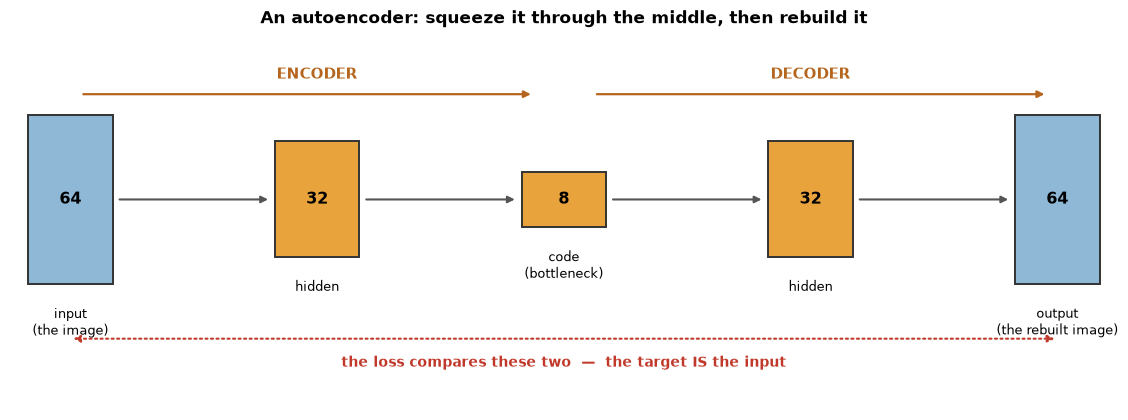

In [ ]:
draw_autoencoder_architecture(dims=(64, 32, 8, 32, 64))
plt.show()


Without the narrow middle, the network would learn the identity function — copy the input to the
output, scoring a perfect zero loss and learning nothing. The bottleneck makes that impossible.
64 numbers must pass through 8, so the network has to discover **what in a digit is worth keeping**.

Two names for the two halves:

* the **encoder** maps an image to a short vector — its **code**, or **latent representation**;
* the **decoder** maps a code back to an image.

After training you can throw the decoder away and keep the encoder, which is now a learned
compressor — and that is usually the thing you actually wanted.

### Exercise 1 — build the hourglass

`nn.Sequential` chains layers without writing a `forward` for each one. The `nn.Sigmoid()` at the
end squashes outputs into 0–1, matching our scaled pixels.

In [ ]:
class Autoencoder(nn.Module):

    def __init__(self, latent=8, hidden=32):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(64, hidden), nn.ReLU(), nn.Linear(hidden, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 64), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x))
torch.manual_seed(0)
ae = Autoencoder(latent=8)
print(ae)
code_out = ae.encoder(Xte[:5])
recon = ae(Xte[:5])
print('\n5 images in        :', tuple(Xte[:5].shape))
print('their codes        :', tuple(code_out.shape), '  <- 64 numbers squeezed into 8')
print('rebuilt images     :', tuple(recon.shape))
assert code_out.shape == (5, 8), 'the code should have one row per image, 8 numbers wide'
assert recon.shape == Xte[:5].shape, 'the output must be the same shape as the input'
assert recon.min() >= 0 and recon.max() <= 1, 'Sigmoid should keep outputs in 0-1'


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): Sigmoid()
  )
)

5 images in        : (5, 64)
their codes        : (5, 8)   <- 64 numbers squeezed into 8
rebuilt images     : (5, 64)


---
# Stage 2 · Training it

## Idea 2 — Your Lab 8 loop, with two words changed

Here is last week's training step beside this week's:

| Lab 8 (classification) | Today (autoencoder) |
|---|---|
| `loss = F.cross_entropy(model(xb), yb)` | `loss = F.mse_loss(model(xb), xb)` |
| target is the **label** | target is the **input** |

`zero_grad → forward → backward → step` is untouched. That is the whole change.

Why **MSE** and not cross-entropy? Because the output is no longer a choice between classes — it
is 64 brightness values, and we want each one close to the original. Cross-entropy answers "which
class?"; MSE answers "how far off?". Choosing the loss to match the question is the skill; the
loop never changes.

### Exercise 2 — train it

In [ ]:
def train_autoencoder(model, data, epochs=60, lr=0.001, batch_size=64, seed=0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(data, data), batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, _ in loader:
            optimizer.zero_grad()
            loss = F.mse_loss(model(xb), xb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        history.append(total / len(data))
    return history

def reconstruction_error(model, data):
    model.eval()
    with torch.no_grad():
        return F.mse_loss(model(data), data).item()
torch.manual_seed(0)
ae = Autoencoder(latent=8)
t0 = time.time()
history = train_autoencoder(ae, Xtr, epochs=60)
print(f'trained in {time.time() - t0:.1f}s')
print(f'epoch  1 loss : {history[0]:.4f}')
print(f'epoch 60 loss : {history[-1]:.4f}')
print(f'\ntest reconstruction error : {reconstruction_error(ae, Xte):.4f}')
assert history[-1] < history[0] / 2, 'the loss should fall a long way; check your MSE target'
assert reconstruction_error(ae, Xte) < 0.04, 'something is wrong - expect about 0.022'


trained in 7.9s
epoch  1 loss : 0.1782
epoch 60 loss : 0.0216

test reconstruction error : 0.0219


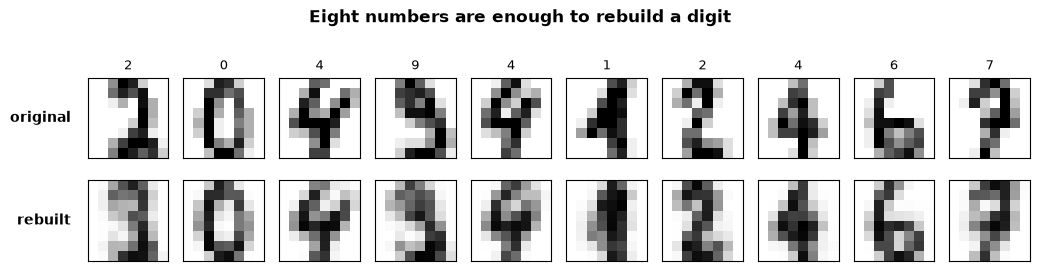

In [ ]:
ae.eval()
with torch.no_grad():
    rebuilt = ae(Xte[:10]).numpy()
draw_digit_grid([('original', X_test[:10]), ('rebuilt', rebuilt)], titles=y_test[:10], suptitle='Eight numbers are enough to rebuild a digit')
plt.show()


Look carefully at the bottom row. The digits are blurrier, and some strokes have thinned — but
every one is still readable. **Those images were reconstructed from 8 numbers each.** The network
was never told what a digit is; it worked out what to keep purely from the pressure of the
bottleneck.

### Checkpoint 1

1. We used `F.mse_loss(model(xb), xb)`. What would happen if the second argument were `yb` — and
   what would the network then be?
2. An autoencoder with a 64-neuron bottleneck and no other change could reach a loss of exactly
   zero. How, and why is that useless?
3. Autoencoders are called unsupervised, yet the training loop still has a target and a loss.
   Explain why the label "unsupervised" is still fair.

**Answers**

1. Digit labels have shape `(batch,)`, whereas the reconstruction has shape `(batch, 64)`. Replacing the target with `yb` would cause a shape error or unintended broadcasting for some batch sizes; it would not create a valid classifier. To train a supervised digit classifier, use ten output logits and a classification loss such as cross-entropy against the digit labels.
2. A sufficiently expressive autoencoder without a restrictive bottleneck can learn to copy its input, which provides no useful compression or requirement to extract a compact representation. However, simply changing `latent` to 64 in **this** architecture leaves both 32-neuron hidden layers in place, so it does not remove all bottlenecks or guarantee zero loss. Also, a finite-logit sigmoid only approaches exact 0 and 1. An unconstrained linear identity mapping could reconstruct inputs exactly; the stated one-argument change is not sufficient to guarantee that result here.
3. The target is derived from the input rather than supplied as a human class annotation. This is commonly called unsupervised representation learning, or self-supervised learning because the data supplies its own reconstruction target.


---
# Stage 3 · How tight can the bottleneck get?

## Idea 3 — The compression dial

The code size is a dial between two extremes. Wide enough and the network copies its input,
learning nothing. One neuron imposes very strong compression. Somewhere between is the interesting part.

### Exercise 3 — sweep it

Train one autoencoder per code size and record the error. Each run takes about two seconds.


In [ ]:
sizes = [2, 4, 8, 16, 32]
train_mse, test_mse = ([], [])
sweep_models = {}
for latent in sizes:
    torch.manual_seed(0)
    model = Autoencoder(latent=latent)
    train_autoencoder(model, Xtr, epochs=60)
    train_mse.append(reconstruction_error(model, Xtr))
    test_mse.append(reconstruction_error(model, Xte))
    sweep_models[latent] = model
    print(f'latent {latent:2d}  train {train_mse[-1]:.4f}  test {test_mse[-1]:.4f}')
average_image = Xtr.mean(dim=0, keepdim=True)
baseline = F.mse_loss(average_image.expand_as(Xte), Xte).item()
print(f'\npredicting the average image : {baseline:.4f}')
assert len(test_mse) == 5, 'one error per code size'
assert test_mse[0] > test_mse[-1], 'a wider code should rebuild better'


latent  2  train 0.0467  test 0.0479


latent  4  train 0.0346  test 0.0368


latent  8  train 0.0213  test 0.0219


latent 16  train 0.0193  test 0.0203


latent 32  train 0.0179  test 0.0190

predicting the average image : 0.0740


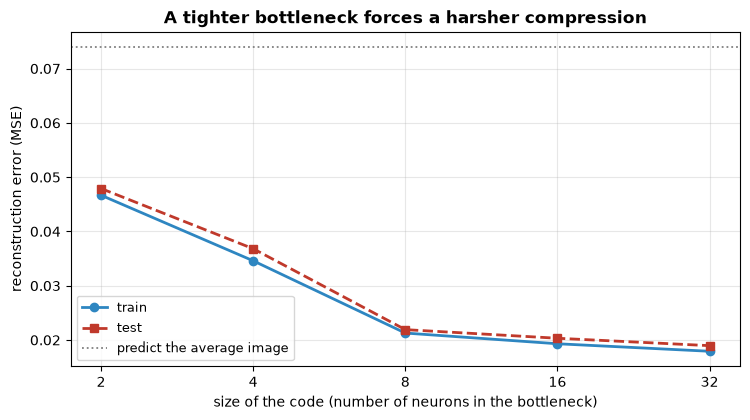

In [ ]:
draw_bottleneck_sweep(sizes, train_mse, test_mse, baseline=baseline)
plt.show()


## Completed bottleneck measurements and PCA comparison

The table below fills the requested reconstruction results from the actual training runs. Compression is the reduction in the number of scalar coordinates, `64 / latent`; it is not a measurement of stored file size and does not include model weights.

PCA is fitted only on the training images, then used to reconstruct the held-out test images. Both methods are evaluated on the same split with the same pixel scaling. The measured comparison replaces the template's illustrative fixed numbers. Wider codes can improve reconstruction, but the shared 32-neuron hidden layers and finite training time also constrain the autoencoder. Inspect the measured train–test gap rather than assuming overfitting is impossible.

A linear autoencoder trained to the appropriate optimum can span the same reconstruction subspace as PCA. This lab's ReLU hidden layers and sigmoid output make its model nonlinear. PCA is a useful baseline whose optimal linear subspace can be computed directly.


In [ ]:
from sklearn.decomposition import PCA
from IPython.display import Markdown, display
pca_mse = []
table = ['| Code size | Compression | Train MSE | Test MSE | PCA test MSE |', '|---|---|---|---|---|']
for latent, tr_error, te_error in zip(sizes, train_mse, test_mse):
    pca = PCA(n_components=latent, svd_solver='full').fit(X_train)
    pca_rebuilt = pca.inverse_transform(pca.transform(X_test))
    pca_error = float(np.mean((pca_rebuilt - X_test) ** 2))
    pca_mse.append(pca_error)
    table.append(f'| {latent} | {64 / latent:g}x | {tr_error:.5f} | {te_error:.5f} | {pca_error:.5f} |')
display(Markdown('\n'.join(table)))


| Code size | Compression | Train MSE | Test MSE | PCA test MSE |
|---|---|---|---|---|
| 2 | 32x | 0.04667 | 0.04791 | 0.05302 |
| 4 | 16x | 0.03459 | 0.03682 | 0.03819 |
| 8 | 8x | 0.02128 | 0.02191 | 0.02461 |
| 16 | 4x | 0.01931 | 0.02032 | 0.01154 |
| 32 | 2x | 0.01792 | 0.01895 | 0.00264 |

---
# Stage 4 · What is inside the code?

## Idea 5 — The encoder is the prize

Train the autoencoder, discard the decoder, keep the encoder: you now have a function that turns
a 64-pixel image into 8 meaningful numbers, learned **without a single label**. That is
**representation learning**, and it is the reason this architecture matters far beyond image
compression.

The test of a representation is whether other things can use it. Let us look at it, then measure it.

### Exercise 4 — look at a 2-D code

codes: (450, 2)  <- two numbers per image


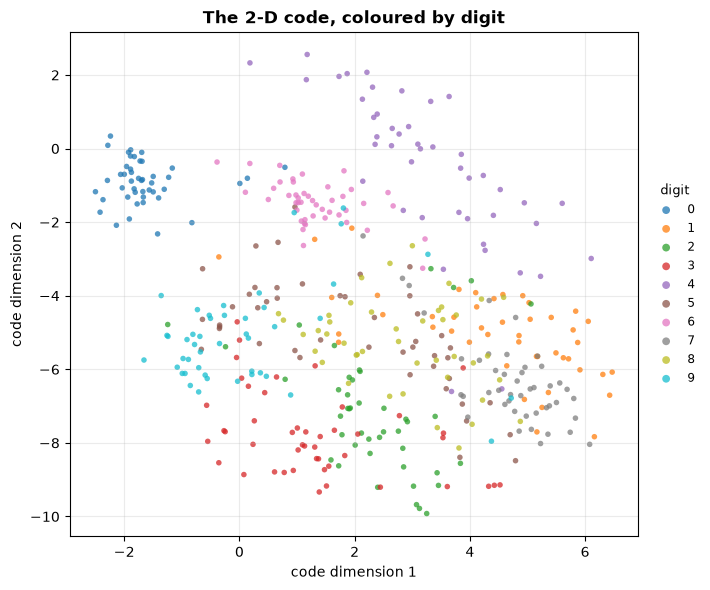

In [ ]:
torch.manual_seed(0)
ae2 = Autoencoder(latent=2)
train_autoencoder(ae2, Xtr, epochs=60)
ae2.eval()
with torch.no_grad():
    Z = ae2.encoder(Xte).numpy()
print('codes:', Z.shape, ' <- two numbers per image')
draw_latent_space(Z, y_test)
plt.show()
assert Z.shape == (450, 2), 'one 2-number code per test image'


Nobody told it about digits. The colours come from labels we never used in training, yet some
classes have landed in their own regions — the zeros in particular — while others are piled on top
of each other.

That is what a two-number summary of a digit looks like: **real structure, not enough of it.**

### Exercise 5 — measure the representation

A picture is suggestive; a number is evidence. Fit a plain logistic regression on the codes and see
how much class information survived the squeeze.

In [ ]:
from sklearn.linear_model import LogisticRegression

def codes_of(model, data):
    model.eval()
    with torch.no_grad():
        return model.encoder(data).numpy()
scores = {}
for latent in [2, 8]:
    torch.manual_seed(0)
    model = Autoencoder(latent=latent)
    train_autoencoder(model, Xtr, epochs=60)
    Ztr = codes_of(model, Xtr)
    Zte = codes_of(model, Xte)
    clf = LogisticRegression(max_iter=2000).fit(Ztr, y_train)
    scores[f'{latent}-number code'] = clf.score(Zte, y_test)
raw = LogisticRegression(max_iter=2000).fit(X_train, y_train)
scores['all 64 pixels'] = raw.score(X_test, y_test)
for name, s in scores.items():
    print(f'{name:18} test accuracy {s:.3f}')
assert scores['8-number code'] > scores['2-number code'], '8 numbers should carry more'


2-number code      test accuracy 0.622
8-number code      test accuracy 0.924
all 64 pixels      test accuracy 0.969


The printed accuracies quantify how much information useful for a linear classifier survives in the learned codes. An 8-dimensional code uses 87.5% fewer coordinates than the 64-pixel input. Its classification accuracy should be judged against the measured raw-pixel baseline, rather than assuming the information loss is negligible.

The autoencoders are trained without digit labels. The logistic regression stage is supervised and uses training labels; test labels are used only to report classification accuracy.

### Checkpoint 2

1. The autoencoder never saw `y_train`. How, then, did its codes end up useful for classifying?
2. You have 50,000 unlabelled images and 200 labelled ones. Describe how you would use an autoencoder, and say which part you would keep.
3. The 2-D picture put several digits on top of one another. Name one pair you would expect to overlap, and say why in terms of the pixels.

**Answers**

1. Reconstruction requires preserving stroke shapes and other visual structure. Those features are correlated with digit identity, so a classifier can exploit them even though labels were not used to train the encoder.
2. Train an autoencoder on the unlabelled training images and keep its encoder. Encode the labelled examples and train a small classifier on those representations. Reserve labelled validation and test examples for model selection and final evaluation; do not use their labels to fit the encoder or classifier. The decoder is unnecessary for the final classification task.
3. Digits **3 and 8** could overlap because both can contain upper and lower curved strokes. At 8 × 8 resolution, handwriting variation and compression into two coordinates can discard the left-side closure that helps distinguish them. This is an expected visual ambiguity, not a claim that every example of those digits occupies the same position.


---
# Stage 5 · Denoising

## Idea 6 — Break the input on purpose

A **denoising autoencoder** changes one thing: corrupt the input, but keep the target clean.

```python
noisy = torch.clamp(xb + 0.5 * torch.randn_like(xb), 0, 1)
loss  = F.mse_loss(model(noisy), xb)         # input damaged, target not
```

Now copying is not just hard, it is *wrong* — reproducing the noise would be penalised. The
network must learn what a digit looks like well enough to put back what was removed. This is the
same instinct as Lab 6's dropout: make the task harder on purpose and a better solution comes out.

### Exercise 6 — train one

In [ ]:
def train_denoising(model, data, noise=0.5, epochs=60, lr=0.001, batch_size=64, seed=0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(data, data), batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    for epoch in range(epochs):
        model.train()
        for xb, _ in loader:
            noisy = torch.clamp(xb + noise * torch.randn_like(xb), 0, 1)
            optimizer.zero_grad()
            loss = F.mse_loss(model(noisy), xb)
            loss.backward()
            optimizer.step()
    return model
torch.manual_seed(0)
plain = Autoencoder(latent=8)
train_autoencoder(plain, Xtr, epochs=60)
torch.manual_seed(0)
denoiser = Autoencoder(latent=8)
train_denoising(denoiser, Xtr, noise=0.5, epochs=60)
torch.manual_seed(7)
Xte_noisy = torch.clamp(Xte + 0.5 * torch.randn_like(Xte), 0, 1)

def mse_against_clean(model, inputs):
    model.eval()
    with torch.no_grad():
        return F.mse_loss(model(inputs), Xte).item()
print(f"{'':24}{'clean input':>13}{'noisy input':>14}")
print(f"{'plain autoencoder':24}{mse_against_clean(plain, Xte):13.4f}{mse_against_clean(plain, Xte_noisy):14.4f}")
print(f"{'denoising autoencoder':24}{mse_against_clean(denoiser, Xte):13.4f}{mse_against_clean(denoiser, Xte_noisy):14.4f}")
print(f"{'do nothing at all':24}{'-':>13}{F.mse_loss(Xte_noisy, Xte).item():14.4f}")
assert mse_against_clean(denoiser, Xte_noisy) < mse_against_clean(plain, Xte_noisy), 'the denoiser should handle noise better - is your target the CLEAN xb?'


                          clean input   noisy input
plain autoencoder              0.0219        0.0534
denoising autoencoder          0.0315        0.0436
do nothing at all                   -        0.1157


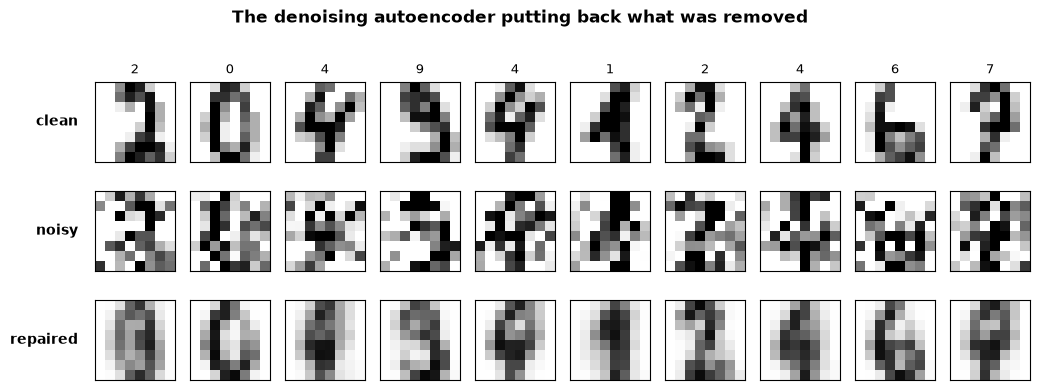

In [ ]:
denoiser.eval()
with torch.no_grad():
    cleaned = denoiser(Xte_noisy[:10]).numpy()
draw_digit_grid([('clean', X_test[:10]), ('noisy', Xte_noisy[:10].numpy()), ('repaired', cleaned)], titles=y_test[:10], suptitle='The denoising autoencoder putting back what was removed')
plt.show()


The clean-input and noisy-input columns measure different operating conditions against the same clean test targets. A denoising model is trained to reconstruct clean digits from corrupted inputs, while the plain autoencoder is trained on clean inputs. Compare both columns to assess the tradeoff: robustness to this noise distribution can come with worse clean-input reconstruction. The unchanged noisy input provides a third baseline.


## Final verification

In [ ]:
assert Xtr.shape == (1347, 64) and Xte.shape == (450, 64)
assert len(history) == 60 and np.isfinite(history).all()
assert len(train_mse) == len(test_mse) == len(pca_mse) == 5
assert np.isfinite(train_mse).all() and np.isfinite(test_mse).all() and np.isfinite(pca_mse).all()
assert all((error < baseline for error in test_mse))
assert all((0 <= accuracy <= 1 for accuracy in scores.values()))
assert Z.shape == (450, 2) and np.isfinite(Z).all()
for trained_model in (ae, ae2, plain, denoiser, *sweep_models.values()):
    trained_model.eval()
    with torch.no_grad():
        outputs = trained_model(Xte)
    assert outputs.shape == Xte.shape
    assert torch.isfinite(outputs).all()
    assert torch.all((outputs >= 0) & (outputs <= 1))
assert mse_against_clean(denoiser, Xte_noisy) < F.mse_loss(Xte_noisy, Xte).item()
print('All original exercise checks and final reconstruction, representation and denoising checks passed.')


All original exercise checks and final reconstruction, representation and denoising checks passed.


---

## What you did today

The first architecture in this course whose goal was not classification.

| | |
|---|---|
| **the shape** | encoder → bottleneck → decoder, trained on `MSE(output, input)` |
| **the trick** | a code too small to hold the input forces the network to choose what matters |
| **the prize** | the encoder — a compressor learned from unlabelled data |
| **denoising** | corrupt the input, keep the target clean, get robustness for a small cost |
| **anomaly detection** | train on normal, alarm on whatever rebuilds badly |

And the loop never changed. `zero_grad → forward → backward → step`, with a different loss and a
different target. That is now three architectures — dense, recurrent, autoencoder — through the
same four lines.

### A gap worth naming

The decoder can turn a code into an image. So could you *invent* a code — pick two numbers at
random, decode them, and get a new digit? Try it and you will mostly get smudges, because nothing
in the training forced the space between the codes to mean anything.

Fixing that is the whole idea of the **variational** autoencoder, which is Lab 11.


### Before next week

* Restart the kernel and run everything top to bottom. Every assertion should pass.
* Spend ten minutes in the [Embedding Projector](https://projector.tensorflow.org/). Load MNIST,
  and look at the same thing you plotted today with far more data behind it.

**End of notebook**